
# مشروع تعلم الآلة النهائي
## التنبؤ بتأخر الطالب في سداد القسط الدراسي

هذا الملف مبني من الصفر ليغطي مسار المشروع كاملًا، من قراءة الداتا وتنظيفها حتى حفظ النموذج والنتائج التي سيستخدمها الـ Backend والـ Frontend.

### ما الذي سينتجه هذا الـ Notebook؟

بعد تشغيل جميع الخلايا سيُنشأ داخل المشروع:

```text
data/
├── dataset-students.xlsx
└── dataset-students-cleaned.csv

models/
├── student_payment_classifier.joblib
├── student_payment_classifier_metadata.json
└── model_comparison.json

research/
└── figures/
    ├── target_distribution.png
    ├── model_comparison.png
    ├── confusion_matrix.png
    ├── roc_curve.png
    ├── precision_recall_curve.png
    └── feature_importance.png
```

### قرار المشروع

سنستخدم **ثلاثة نماذج مرشحة**:

1. Logistic Regression
2. Random Forest
3. SVM

ثم:
- نضبط Hyperparameters لكل نموذج.
- نقارن بينها باستخدام Accuracy و Precision و Recall و F1-score.
- نختار النموذج الأفضل حسب **F1-score**.
- نحفظ النموذج الأفضل فقط ليصدر القرار النهائي.
- نحفظ نتائج النماذج الثلاثة في `model_comparison.json` لكي يعرضها الـ Frontend كمقارنة توضيحية أسفل نتيجة التنبؤ.

> الحالة الإيجابية `1` في هذا المشروع تعني: **الطالب متأخر في السداد**.



# 0. تثبيت المكتبات عند الحاجة

إذا ظهرت لك رسالة أن مكتبة غير موجودة، شغّل الخلية التالية بعد إزالة `#` من أول السطر، ثم أعد تشغيل الـ Kernel.

```python
# !pip install pandas numpy matplotlib scikit-learn openpyxl joblib
```


In [1]:

# !pip install pandas numpy matplotlib scikit-learn openpyxl joblib


# 1. استيراد المكتبات

In [2]:

from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("تم تحميل المكتبات بنجاح.")


تم تحميل المكتبات بنجاح.



# 2. تحديد مسارات المشروع

الخلية تعمل في الحالات الشائعة التالية:

- تشغيل Jupyter من جذر المشروع.
- تشغيل الـ Notebook وهو داخل `notebooks`.
- وضع الـ Dataset بجانب الـ Notebook مؤقتًا.

الترتيب المقترح:

```text
project/
├── data/
│   └── dataset-students.xlsx
├── models/
├── notebooks/
│   └── 01_student_payment_model_complete.ipynb
├── research/
└── backend/
```


In [3]:
cwd = Path.cwd()

candidate_beside_notebook = cwd / "dataset-students.xlsx"
candidate_from_root = cwd / "data" / "dataset-students.xlsx"
candidate_from_notebooks = cwd.parent / "data" / "dataset-students.xlsx"

if candidate_beside_notebook.exists():
    # مناسب عندما يكون الملف بجانب الـ Notebook مؤقتًا
    DATA_PATH = candidate_beside_notebook
    PROJECT_ROOT = cwd

elif candidate_from_root.exists():
    # مناسب عند تشغيل Jupyter من جذر المشروع
    DATA_PATH = candidate_from_root
    PROJECT_ROOT = cwd

elif candidate_from_notebooks.exists():
    # مناسب عندما يكون الـ Notebook داخل مجلد notebooks
    DATA_PATH = candidate_from_notebooks
    PROJECT_ROOT = cwd.parent

else:
    raise FileNotFoundError(
        "لم يتم العثور على dataset-students.xlsx.\n"
        "ضع الملف داخل مجلد data في جذر المشروع."
    )

DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
RESEARCH_DIR = PROJECT_ROOT / "research"
FIGURES_DIR = RESEARCH_DIR / "figures"

DATA_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT :", PROJECT_ROOT)
print("DATA_PATH    :", DATA_PATH)
print("MODELS_DIR   :", MODELS_DIR)
print("FIGURES_DIR  :", FIGURES_DIR)

PROJECT_ROOT : C:\Users\abdalmohaymen\Downloads\mlproject
DATA_PATH    : C:\Users\abdalmohaymen\Downloads\mlproject\data\dataset-students.xlsx
MODELS_DIR   : C:\Users\abdalmohaymen\Downloads\mlproject\models
FIGURES_DIR  : C:\Users\abdalmohaymen\Downloads\mlproject\research\figures


# 3. قراءة البيانات الأصلية

In [4]:

df_raw = pd.read_excel(DATA_PATH)

print("عدد الصفوف:", df_raw.shape[0])
print("عدد الأعمدة:", df_raw.shape[1])

df_raw.head()


عدد الصفوف: 264
عدد الأعمدة: 22


,طابع زمني,الفرع,قيمة القسط التقريببة,من المسؤول عن دفع القسط,هل تعمل الى جانب الدراسة,المحافظة,عدد الساعات لمسجل عليها,هل سبق وأن تأخر في سداد القسط عن الموعد المحدد,المعدل التراكمي التقريبي من 100,نسبة الحضور في جميع المقررات من 100,عدد المرات التي تأخرت بها عن تسديد القسط,اقصى مدة زمنية تأخرت بها عن تسديد القسط بالايام,عدد المرات التي لم تتأخر بها عن تسديد القسط,الدخل المالي الشهري للعائلة بالدولار حصرا,عدد الاخوة والاخوات الطلاب في التعليم الجامعي الخاص,قيمة القسط الفصلي بشكل تقديري,هل سددت القسط الأخير في موعده,السنة الدراسية,عدد الاشخاص العاملين بالاسرة,هل توجد أقساط جامعية سابقة غير مسددة,السكن,بعد سكن الطالب عن مركز الجامعة بالكيلو متر
0,2026-08-17 03:33:16.711,الهندسة المعلوماتية,NaN,الطالب,نعم,ادلب,6.0,نعم,65.0,50,2.0,10.0,10,بين 100 و 200,1.000000,150.0,نعم,خامسة,2.0,نعم,ملك,100.0
1,2026-08-17 03:33:59.547,كلية الهندسة المعلوماتية,NaN,الأسرة(اب-أم),نعم,حلب,9.0,نعم,70.0,90,3.0,2.0,10,بين 100 و 200,1.000000,150.0,نعم,خامسة,1.0,لا,ملك,3.0
2,2026-08-17 03:35:00.270,معلوماتيه,NaN,الأسرة(اب-أم),لا,حلب,9.0,لا,75.0,75,1.0,1.0,6,اقل من 100,1.000000,400.0,نعم,ثالثة,1.0,لا,ملك,5.0
3,2026-08-17 03:36:31.111,هندسة معلوماتية,NaN,الأسرة(اب-أم),لا,ادلب,18.0,لا,85.0,95,1.0,3.0,8,بين 200 و 500,0.000001,200.0,نعم,رابعة,2.0,لا,ايجار,7.0
4,2026-08-17 03:36:38.551,هندسة معلوماتية,NaN,الطالب,نعم,حلب,117.0,نعم,80.0,40,2.0,15.0,5,بين 200 و 500,1.000000,400.0,نعم,ثالثة,3.0,لا,ملك,40.0


# 4. فحص البيانات قبل أي تعديل

In [5]:

print("Shape:", df_raw.shape)
print("\nعدد الصفوف المكررة تمامًا:", df_raw.duplicated().sum())

print("\nأسماء الأعمدة:")
for i, col in enumerate(df_raw.columns, start=1):
    print(f"{i:02d}. {repr(col)}")


Shape: (264, 22)

عدد الصفوف المكررة تمامًا: 3

أسماء الأعمدة:
01. 'طابع زمني'
02. 'الفرع'
03. 'قيمة القسط التقريببة'
04. 'من المسؤول عن دفع القسط'
05. 'هل تعمل الى جانب الدراسة'
06. 'المحافظة'
07. 'عدد الساعات لمسجل عليها'
08. 'هل سبق وأن تأخر في سداد القسط عن الموعد المحدد'
09. 'المعدل التراكمي التقريبي من 100'
10. 'نسبة الحضور في جميع المقررات من 100'
11. 'عدد المرات التي تأخرت بها عن تسديد القسط'
12. 'اقصى مدة زمنية تأخرت بها عن تسديد القسط بالايام '
13. 'عدد المرات التي لم تتأخر بها عن تسديد القسط'
14. 'الدخل المالي الشهري للعائلة بالدولار حصرا '
15. 'عدد الاخوة والاخوات الطلاب في التعليم الجامعي الخاص '
16. 'قيمة القسط الفصلي بشكل تقديري'
17. '  هل سددت القسط الأخير في موعده  '
18. 'السنة الدراسية'
19. 'عدد الاشخاص العاملين بالاسرة'
20. 'هل توجد أقساط جامعية سابقة غير مسددة'
21. 'السكن'
22. 'بعد سكن الطالب عن مركز الجامعة بالكيلو متر'


In [6]:

initial_summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(dropna=False)
}).sort_values("missing_percent", ascending=False)

initial_summary


,dtype,missing_count,missing_percent,unique_values
قيمة القسط التقريببة,float64,65,24.62,37
عدد الساعات لمسجل عليها,float64,3,1.14,13
بعد سكن الطالب عن مركز الجامعة بالكيلو متر,float64,1,0.38,215
الدخل المالي الشهري للعائلة بالدولار حصرا,object,1,0.38,7
عدد الاشخاص العاملين بالاسرة,float64,1,0.38,8
المعدل التراكمي التقريبي من 100,float64,1,0.38,128
السكن,object,0,0.00,6
هل توجد أقساط جامعية سابقة غير مسددة,object,0,0.00,3
السنة الدراسية,object,0,0.00,6
هل سددت القسط الأخير في موعده,object,0,0.00,2



# 5. إعادة تسمية الأعمدة

سنحتفظ بمعنى الأعمدة كما هو، لكن نعطيها أسماء إنجليزية قصيرة لتسهيل البرمجة وربط النموذج لاحقًا مع FastAPI.


In [7]:

COLUMN_RENAME_MAP = {
    "طابع زمني": "timestamp",
    "الفرع": "branch",
    "قيمة القسط التقريببة": "approx_installment_value",
    "من المسؤول عن دفع القسط": "payment_responsible",
    "هل تعمل الى جانب الدراسة": "works_while_studying",
    "المحافظة": "governorate",
    "عدد الساعات لمسجل عليها": "registered_hours",
    "هل سبق وأن تأخر في سداد القسط عن الموعد المحدد": "previous_payment_delay",
    "المعدل التراكمي التقريبي من 100": "gpa",
    "نسبة الحضور في جميع المقررات من 100": "attendance_rate",
    "عدد المرات التي تأخرت بها عن تسديد القسط": "delay_count",
    "اقصى مدة زمنية تأخرت بها عن تسديد القسط بالايام ": "max_delay_days",
    "عدد المرات التي لم تتأخر بها عن تسديد القسط": "on_time_payment_count",
    "الدخل المالي الشهري للعائلة بالدولار حصرا ": "family_monthly_income",
    "عدد الاخوة والاخوات الطلاب في التعليم الجامعي الخاص ": "private_university_siblings",
    "قيمة القسط الفصلي بشكل تقديري": "semester_fee",
    "  هل سددت القسط الأخير في موعده  ": "paid_last_installment_on_time",
    "السنة الدراسية": "study_year",
    "عدد الاشخاص العاملين بالاسرة": "working_family_members",
    "هل توجد أقساط جامعية سابقة غير مسددة": "previous_unpaid_fees",
    "السكن": "housing",
    "بعد سكن الطالب عن مركز الجامعة بالكيلو متر": "distance_from_university"
}

df = df_raw.rename(columns=COLUMN_RENAME_MAP).copy()

print(df.columns.tolist())


['timestamp', 'branch', 'approx_installment_value', 'payment_responsible', 'works_while_studying', 'governorate', 'registered_hours', 'previous_payment_delay', 'gpa', 'attendance_rate', 'delay_count', 'max_delay_days', 'on_time_payment_count', 'family_monthly_income', 'private_university_siblings', 'semester_fee', 'paid_last_installment_on_time', 'study_year', 'working_family_members', 'previous_unpaid_fees', 'housing', 'distance_from_university']


# 6. قاموس البيانات

In [8]:

data_dictionary = pd.DataFrame([
    ["branch", "الفرع الدراسي", "Categorical"],
    ["approx_installment_value", "قيمة القسط التقريبية", "Numeric"],
    ["payment_responsible", "المسؤول عن دفع القسط", "Categorical"],
    ["works_while_studying", "هل يعمل الطالب إلى جانب الدراسة", "Categorical"],
    ["governorate", "المحافظة", "Categorical"],
    ["registered_hours", "عدد الساعات المسجلة", "Numeric"],
    ["previous_payment_delay", "هل سبق للطالب التأخر في السداد", "Categorical"],
    ["gpa", "المعدل التراكمي من 100", "Numeric"],
    ["attendance_rate", "نسبة الحضور من 100", "Numeric"],
    ["delay_count", "عدد مرات التأخر السابقة", "Numeric"],
    ["max_delay_days", "أقصى مدة تأخير سابقة بالأيام", "Numeric"],
    ["on_time_payment_count", "عدد مرات الدفع دون تأخير", "Numeric"],
    ["family_monthly_income", "دخل الأسرة الشهري ضمن فئة", "Categorical"],
    ["private_university_siblings", "عدد الإخوة في التعليم الجامعي الخاص", "Numeric"],
    ["semester_fee", "قيمة القسط الفصلي", "Numeric"],
    ["paid_last_installment_on_time", "هل سُدد القسط الأخير في موعده", "TARGET"],
    ["study_year", "السنة الدراسية", "Categorical"],
    ["working_family_members", "عدد العاملين في الأسرة", "Numeric"],
    ["previous_unpaid_fees", "وجود أقساط جامعية سابقة غير مسددة", "Categorical"],
    ["housing", "نوع السكن", "Categorical"],
    ["distance_from_university", "المسافة عن الجامعة بالكيلومتر", "Numeric"]
], columns=["column", "meaning", "type"])

data_dictionary


,column,meaning,type
0,branch,الفرع الدراسي,Categorical
1,approx_installment_value,قيمة القسط التقريبية,Numeric
2,payment_responsible,المسؤول عن دفع القسط,Categorical
3,works_while_studying,هل يعمل الطالب إلى جانب الدراسة,Categorical
4,governorate,المحافظة,Categorical
5,registered_hours,عدد الساعات المسجلة,Numeric
6,previous_payment_delay,هل سبق للطالب التأخر في السداد,Categorical
7,gpa,المعدل التراكمي من 100,Numeric
8,attendance_rate,نسبة الحضور من 100,Numeric
9,delay_count,عدد مرات التأخر السابقة,Numeric



# 7. تنظيف النصوص

نعالج:
- المسافات الزائدة.
- المسافات في بداية ونهاية النص.
- محارف الاتجاه المخفية.
- المسافات غير القابلة للكسر.


In [9]:

def clean_text(value):
    if pd.isna(value):
        return np.nan

    value = str(value)
    value = value.replace("\u200f", "")
    value = value.replace("\u200e", "")
    value = value.replace("\xa0", " ")
    value = re.sub(r"\s+", " ", value).strip()

    return value


object_columns = df.select_dtypes(include="object").columns

for col in object_columns:
    df[col] = df[col].map(clean_text)

print("تم تنظيف النصوص.")


تم تنظيف النصوص.


## 7.1 عرض القيم الفئوية قبل توحيد الأخطاء

In [10]:

for col in df.select_dtypes(include="object").columns:
    print("\n" + "=" * 80)
    print(col)
    print(df[col].value_counts(dropna=False))



branch
branch
كلية الهندسة المعلوماتية       52
معهد أمن المعلومات والشبكات    28
كلية الهندسة المدنية           20
كلية التمريض                   19
هندسة معلوماتية                19
كلية الصيدلة                   19
كلية إدارة الأعمال             18
كلية الهندسة المعمارية         18
معهد نظم المعلومات الإدارية    18
الهندسة المعلوماتية            11
كلية الحقوق                    11
كلية الاقتصاد                  10
معلوماتية                       3
معهد امن المعلومات              2
هندسه معلوماتية                 2
الهندسة                         1
هندسة معلوماتيه                 1
نظم المعلومات الإدارية          1
مصطفى محمد السماعيل             1
هتدسة معلوماتية                 1
كلية هندسة معلوماتية            1
معلوطاتية                       1
احمد عبد الله عبد القادر        1
أمن معلومات وشبكات              1
الهندسه المعلوماتية             1
هندسة المعلوماتية               1
المعلوماتية                     1
معلوماتيه                       1
كلية الهندسة المعلومايتة        1


# 8. توحيد الفئات المتكررة والأخطاء الكتابية

هذه القواعد مبنية على القيم الموجودة فعليًا في الـ Dataset.

نقوم بتوحيد الصيغ المختلفة لنفس المعنى، ولا نحاول تخمين الفرع عندما تكون القيمة اسم شخص أو كلمة غامضة.


In [11]:

branch_replacements = {
    "هندسة معلوماتية": "كلية الهندسة المعلوماتية",
    "الهندسة المعلوماتية": "كلية الهندسة المعلوماتية",
    "الهندسه المعلوماتية": "كلية الهندسة المعلوماتية",
    "هندسة المعلوماتية": "كلية الهندسة المعلوماتية",
    "معلوماتية": "كلية الهندسة المعلوماتية",
    "معلوماتيه": "كلية الهندسة المعلوماتية",
    "المعلوماتية": "كلية الهندسة المعلوماتية",
    "هندسة معلوماتيه": "كلية الهندسة المعلوماتية",
    "هندسه معلوماتية": "كلية الهندسة المعلوماتية",
    "كلية هندسة معلوماتية": "كلية الهندسة المعلوماتية",
    "كلية الهندسة المعلومايتة": "كلية الهندسة المعلوماتية",
    "هتدسة معلوماتية": "كلية الهندسة المعلوماتية",
    "معلوطاتية": "كلية الهندسة المعلوماتية",

    "معهد امن المعلومات": "معهد أمن المعلومات والشبكات",
    "أمن معلومات وشبكات": "معهد أمن المعلومات والشبكات",

    "نظم المعلومات الإدارية": "معهد نظم المعلومات الإدارية"
}

df["branch"] = df["branch"].replace(branch_replacements)

# قيم لا يمكن تحديد الفرع الصحيح منها بثقة
invalid_branch_values = {
    "احمد عبد الله عبد القادر",
    "مصطفى محمد السماعيل",
    "الهندسة"
}

df.loc[df["branch"].isin(invalid_branch_values), "branch"] = np.nan


df["payment_responsible"] = df["payment_responsible"].replace({
    "الاسرة": "الأسرة(اب-أم)"
})

df["governorate"] = df["governorate"].replace({
    "ادلب": "إدلب",
    "حماه": "حماة",
    "حلبب": "حلب"
})

df["family_monthly_income"] = df["family_monthly_income"].replace({
    "بين 200-500": "بين 200 و 500"
})

df["study_year"] = df["study_year"].replace({
    "سنة أولى": "أولى"
})

df["housing"] = df["housing"].replace({
    "إيجار": "ايجار"
})

print("تم توحيد القيم الفئوية.")


تم توحيد القيم الفئوية.


## 8.1 التحقق من أهم الفئات بعد التوحيد

In [12]:

for col in [
    "branch",
    "payment_responsible",
    "works_while_studying",
    "governorate",
    "family_monthly_income",
    "study_year",
    "previous_unpaid_fees",
    "housing"
]:
    print("\n" + "-" * 70)
    print(col)
    print(df[col].value_counts(dropna=False))



----------------------------------------------------------------------
branch
branch
كلية الهندسة المعلوماتية       96
معهد أمن المعلومات والشبكات    31
كلية الهندسة المدنية           20
معهد نظم المعلومات الإدارية    19
كلية الصيدلة                   19
كلية التمريض                   19
كلية الهندسة المعمارية         18
كلية إدارة الأعمال             18
كلية الحقوق                    11
كلية الاقتصاد                  10
NaN                             3
Name: count, dtype: int64

----------------------------------------------------------------------
payment_responsible
payment_responsible
الأسرة(اب-أم)     119
الطالب            108
الطالب والأسرة     29
منحة/جهة داعمة      8
Name: count, dtype: int64

----------------------------------------------------------------------
works_while_studying
works_while_studying
لا     145
نعم    119
Name: count, dtype: int64

----------------------------------------------------------------------
governorate
governorate
إدلب         84
حلب          7


# 9. التأكد من أنواع الأعمدة الرقمية

نستخدم `pd.to_numeric(..., errors="coerce")`.

إذا كانت هناك قيمة نصية بالخطأ داخل عمود رقمي، تتحول إلى `NaN` بدل أن تتسبب في فشل التدريب.


In [13]:

EXPECTED_NUMERIC_COLUMNS = [
    "approx_installment_value",
    "registered_hours",
    "gpa",
    "attendance_rate",
    "delay_count",
    "max_delay_days",
    "on_time_payment_count",
    "private_university_siblings",
    "semester_fee",
    "working_family_members",
    "distance_from_university"
]

for col in EXPECTED_NUMERIC_COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[EXPECTED_NUMERIC_COLUMNS].dtypes


approx_installment_value       float64
registered_hours               float64
gpa                            float64
attendance_rate                  int64
delay_count                    float64
max_delay_days                 float64
on_time_payment_count            int64
private_university_siblings    float64
semester_fee                   float64
working_family_members         float64
distance_from_university       float64
dtype: object


# 10. معالجة القيم غير المنطقية

لا نحذف كل Outlier تلقائيًا.

نحوّل فقط القيم التي تخالف قواعد منطقية واضحة إلى `NaN`، ثم سيعالجها الـ Imputer داخل Pipeline التدريب.

القواعد المستخدمة هنا:
- المعدل والحضور بين 0 و100.
- الساعات المسجلة بين 0 و30.
- القيم التي تمثل أعدادًا لا يمكن أن تكون سالبة.
- القسط الفصلي بقيمة أقل أو تساوي 10 اعتُبر إدخالًا غير منطقي في هذه الداتا.
- المسافة يجب أن تكون بين 0 و1000 كم؛ القيمة 8000 الموجودة في البيانات تعتبر خطأ إدخال واضحًا.


In [14]:

invalid_value_report = {}

rules = {
    "approx_installment_value":
        (df["approx_installment_value"] <= 0),

    "registered_hours":
        (df["registered_hours"] < 0) |
        (df["registered_hours"] > 30),

    "gpa":
        (df["gpa"] < 0) |
        (df["gpa"] > 100),

    "attendance_rate":
        (df["attendance_rate"] < 0) |
        (df["attendance_rate"] > 100),

    "delay_count":
        (df["delay_count"] < 0),

    "max_delay_days":
        (df["max_delay_days"] < 0),

    "on_time_payment_count":
        (df["on_time_payment_count"] < 0),

    "private_university_siblings":
        (df["private_university_siblings"] < 0),

    "semester_fee":
        (df["semester_fee"] <= 10),

    "working_family_members":
        (df["working_family_members"] < 0),

    "distance_from_university":
        (df["distance_from_university"] < 0) |
        (df["distance_from_university"] > 1000)
}


for col, mask in rules.items():
    count = int(mask.fillna(False).sum())
    invalid_value_report[col] = count

    if count > 0:
        df.loc[mask, col] = np.nan


pd.DataFrame(
    invalid_value_report.items(),
    columns=["column", "invalid_values_converted_to_nan"]
)


,column,invalid_values_converted_to_nan
0,approx_installment_value,0
1,registered_hours,4
2,gpa,0
3,attendance_rate,1
4,delay_count,0
5,max_delay_days,0
6,on_time_payment_count,0
7,private_university_siblings,0
8,semester_fee,2
9,working_family_members,0



# 11. فحص وتصحيح التناقضات الداخلية

لدينا ثلاثة أعمدة تتحدث عن تاريخ التأخر السابق:

- `previous_payment_delay`
- `delay_count`
- `max_delay_days`

إذا كان `delay_count > 0` أو `max_delay_days > 0` فمنطقيًا الطالب سبق أن تأخر.

وإذا كان كلاهما يساوي صفرًا، فمنطقيًا لم يسبق أن تأخر.

سنستخدم العمودين الرقميين معًا لتصحيح العلم النصي `previous_payment_delay`.


In [15]:

before_consistency = df["previous_payment_delay"].copy()

history_known = (
    df["delay_count"].notna() &
    df["max_delay_days"].notna()
)

has_previous_delay = (
    history_known &
    (
        (df["delay_count"] > 0) |
        (df["max_delay_days"] > 0)
    )
)

has_no_previous_delay = (
    history_known &
    (df["delay_count"] == 0) &
    (df["max_delay_days"] == 0)
)

df.loc[has_previous_delay, "previous_payment_delay"] = "نعم"
df.loc[has_no_previous_delay, "previous_payment_delay"] = "لا"

consistency_changes = int(
    (before_consistency != df["previous_payment_delay"]).fillna(False).sum()
)

print("عدد القيم التي تم تصحيحها في previous_payment_delay:", consistency_changes)


عدد القيم التي تم تصحيحها في previous_payment_delay: 89


# 12. حذف الصفوف المكررة

In [16]:

before_rows = len(df)

# لا نستخدم timestamp لتحديد التكرار؛ لأنه ليس Feature للتعلم.
duplicate_subset = [
    col for col in df.columns
    if col != "timestamp"
]

duplicate_count = int(
    df.duplicated(
        subset=duplicate_subset,
        keep="first"
    ).sum()
)

df = df.drop_duplicates(
    subset=duplicate_subset,
    keep="first"
).reset_index(drop=True)

after_rows = len(df)

print("عدد الصفوف قبل:", before_rows)
print("عدد التكرارات المحذوفة:", duplicate_count)
print("عدد الصفوف بعد:", after_rows)


عدد الصفوف قبل: 264
عدد التكرارات المحذوفة: 3
عدد الصفوف بعد: 261


# 13. فحص القيم المفقودة بعد التنظيف

In [17]:

missing_after_cleaning = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

missing_after_cleaning


,missing_count,missing_percent
approx_installment_value,65,24.90
registered_hours,7,2.68
distance_from_university,3,1.15
branch,3,1.15
semester_fee,2,0.77
working_family_members,1,0.38
gpa,1,0.38
attendance_rate,1,0.38
family_monthly_income,1,0.38
private_university_siblings,0,0.00



## لماذا لا نملأ القيم المفقودة الآن؟

التعويض بالـ Median أو Most Frequent يجب أن يتعلم من **Training Set فقط**.

لو حسبنا قيم التعويض من كامل البيانات قبل التقسيم، فإن Test Set سيؤثر بطريقة غير مباشرة على التدريب، وهذا يسمى **Data Leakage**.

لذلك ستبقى القيم المفقودة الآن، وسنعالجها لاحقًا داخل `Pipeline`.


# 14. تقرير القيم الشاذة باستخدام IQR

In [18]:

def iqr_outlier_report(dataframe, columns):
    rows = []

    for col in columns:
        s = dataframe[col].dropna()

        if len(s) == 0:
            continue

        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outlier_count = int(
            ((s < lower_bound) | (s > upper_bound)).sum()
        )

        rows.append({
            "column": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": outlier_count
        })

    return pd.DataFrame(rows).sort_values(
        "outlier_count",
        ascending=False
    )


numeric_columns_now = df.select_dtypes(include=np.number).columns.tolist()

outlier_report = iqr_outlier_report(
    df,
    numeric_columns_now
)

outlier_report


,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
4,delay_count,1.000000,2.000,1.000000,-0.500000,3.500000,43
5,max_delay_days,1.000000,10.000,9.000000,-12.500000,23.500000,32
3,attendance_rate,69.000000,87.000,18.000000,42.000000,114.000000,13
2,gpa,70.000000,82.000,12.000000,52.000000,100.000000,8
8,semester_fee,176.500000,289.500,113.000000,7.000000,459.000000,5
0,approx_installment_value,95.000000,155.000,60.000000,5.000000,245.000000,3
1,registered_hours,9.000000,15.000,6.000000,0.000000,24.000000,2
6,on_time_payment_count,4.000000,9.000,5.000000,-3.500000,16.500000,2
7,private_university_siblings,0.000001,2.000,1.999999,-2.999998,4.999999,1
9,working_family_members,1.000000,3.000,2.000000,-2.000000,6.000000,1



> ملاحظة: تقرير IQR للكشف والتحليل فقط. لا نحذف القيم الشاذة تلقائيًا؛ لأن بعض القيم المتطرفة قد تكون حالات طلاب حقيقية ومهمة للنموذج.


# 15. إنشاء المتغير الهدف Target

In [19]:

print("قيم الهدف الأصلية:")
print(df["paid_last_installment_on_time"].value_counts(dropna=False))


قيم الهدف الأصلية:
paid_last_installment_on_time
نعم    201
لا      60
Name: count, dtype: int64



سننشئ:

`late_payment`

بحيث:
- `0` = دفع القسط الأخير في موعده.
- `1` = لم يدفع في الموعد / متأخر.

اختيار `1 = متأخر` مهم لأن Precision وRecall وF1 ستقيس قدرة النموذج على اكتشاف الطالب المعرض للتأخر.


In [20]:

TARGET_MAP = {
    "نعم": 0,
    "لا": 1
}

df["late_payment"] = df["paid_last_installment_on_time"].map(TARGET_MAP)

unknown_target_count = int(df["late_payment"].isna().sum())

if unknown_target_count > 0:
    raise ValueError(
        f"يوجد {unknown_target_count} قيمة غير معروفة في Target."
    )

print(df["late_payment"].value_counts())
print("\nالنسب:")
print(
    (df["late_payment"].value_counts(normalize=True) * 100)
    .round(2)
)


late_payment
0    201
1     60
Name: count, dtype: int64

النسب:
late_payment
0    77.01
1    22.99
Name: proportion, dtype: float64


# 16. التحليل الاستكشافي EDA

## 16.1 إحصاءات وصفية للأعمدة الرقمية

In [21]:

df.select_dtypes(include=np.number).describe().T


,count,mean,std,min,25%,50%,75%,max
approx_installment_value,196.0,128.494898,44.403799,60.0,95.000000,125.00,155.000,310.0
registered_hours,254.0,12.476378,4.590486,3.0,9.000000,12.00,15.000,27.0
gpa,260.0,75.390769,12.357734,3.0,70.000000,76.45,82.000,98.0
attendance_rate,260.0,75.023077,17.518205,1.0,69.000000,78.00,87.000,100.0
delay_count,261.0,1.865900,2.387714,0.0,1.000000,1.00,2.000,15.0
max_delay_days,261.0,9.206897,17.406545,0.0,1.000000,3.00,10.000,180.0
on_time_payment_count,261.0,6.501916,3.331233,0.0,4.000000,7.00,9.000,20.0
private_university_siblings,261.0,1.111111,0.902513,0.0,0.000001,1.00,2.000,5.0
semester_fee,259.0,244.681467,89.503540,50.0,176.500000,234.00,289.500,560.0
working_family_members,260.0,1.961538,1.016496,0.0,1.000000,2.00,3.000,8.0


## 16.2 توزيع المتغير الهدف

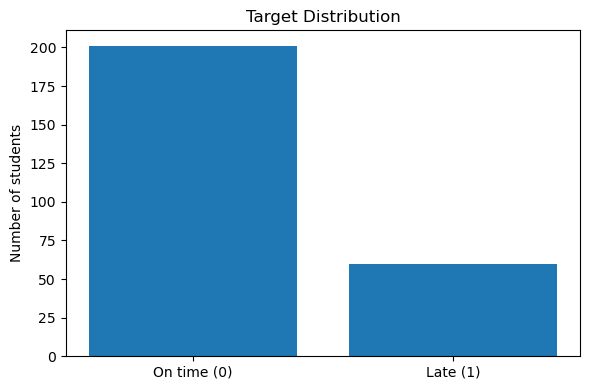

تم حفظ الرسم: C:\Users\abdalmohaymen\Downloads\mlproject\research\figures\target_distribution.png


In [22]:

target_counts = df["late_payment"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    ["On time (0)", "Late (1)"],
    target_counts.values
)

ax.set_title("Target Distribution")
ax.set_ylabel("Number of students")

fig.tight_layout()

figure_path = FIGURES_DIR / "target_distribution.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")

plt.show()

print("تم حفظ الرسم:", figure_path)



إذا كانت فئة المتأخرين أقل من فئة الدفع في الموعد، فإن Accuracy وحدها قد تكون مضللة.

لذلك سنركز على:
- Precision
- Recall
- F1-score

مع عرض Accuracy أيضًا لأن المشروع يطلبها.


## 16.3 توزيعات المتغيرات الرقمية المهمة

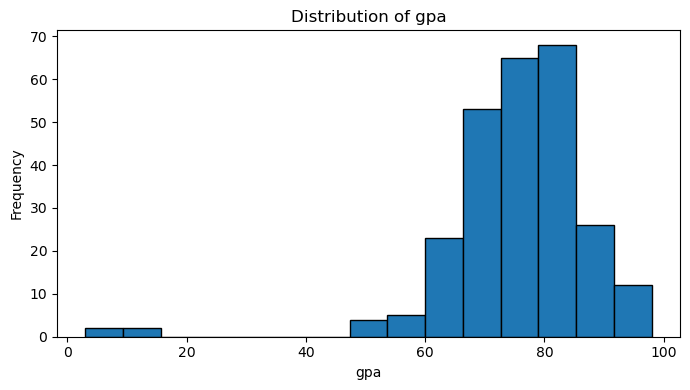

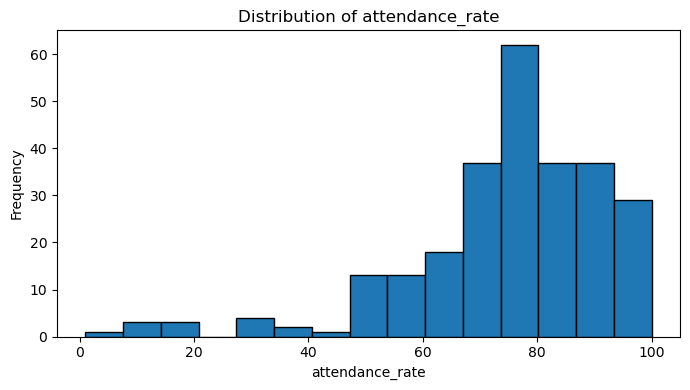

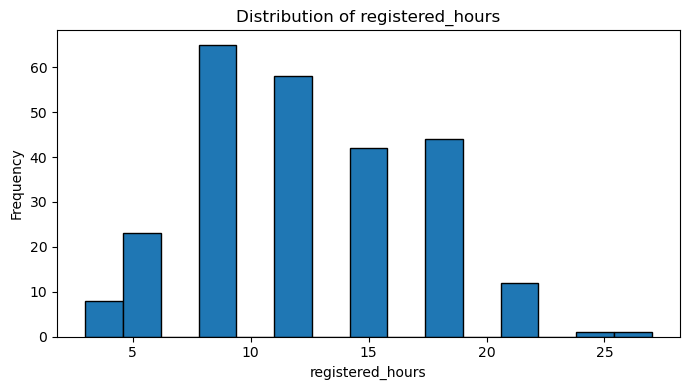

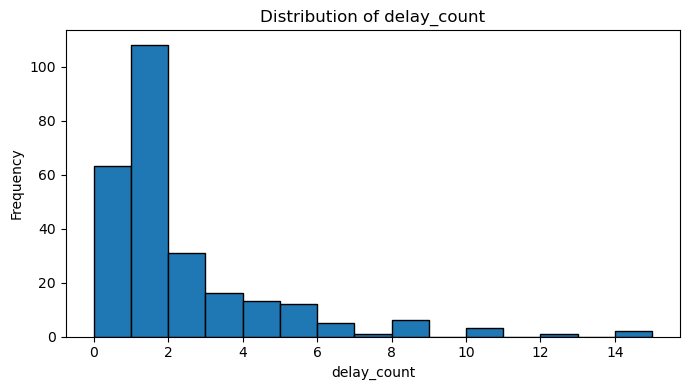

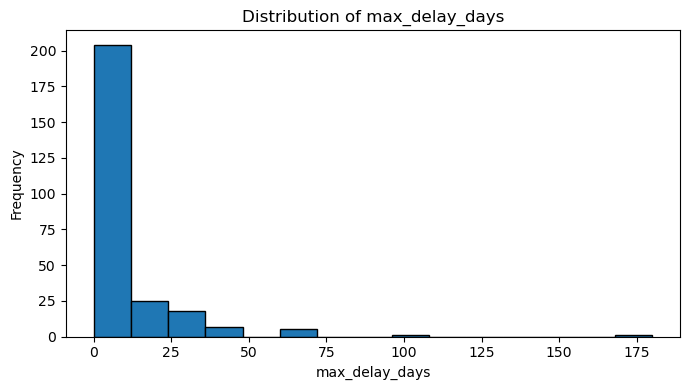

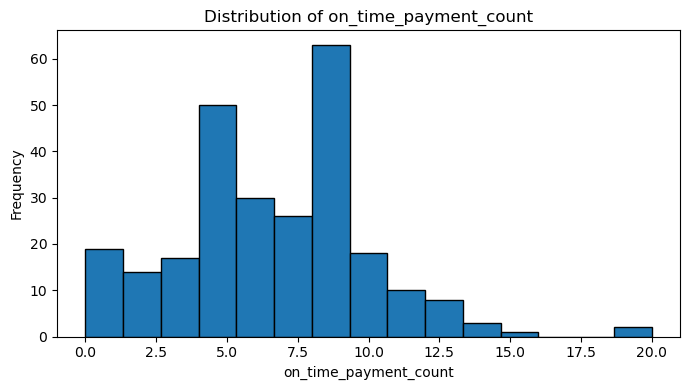

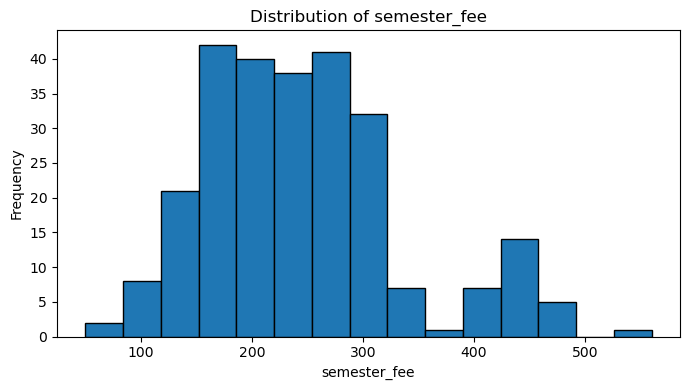

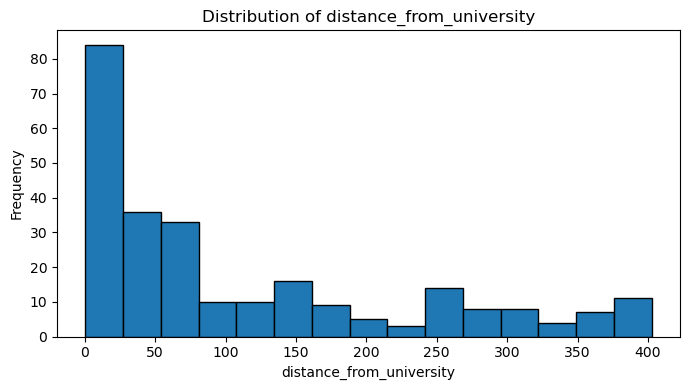

In [23]:

numeric_eda_features = [
    "gpa",
    "attendance_rate",
    "registered_hours",
    "delay_count",
    "max_delay_days",
    "on_time_payment_count",
    "semester_fee",
    "distance_from_university"
]

for col in numeric_eda_features:
    fig, ax = plt.subplots(figsize=(7, 4))

    ax.hist(
        df[col].dropna(),
        bins=15,
        edgecolor="black"
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

    fig.tight_layout()
    plt.show()


## 16.4 مقارنة المتغيرات الرقمية حسب حالة السداد

TypeError: Axes.boxplot() got an unexpected keyword argument 'tick_labels'

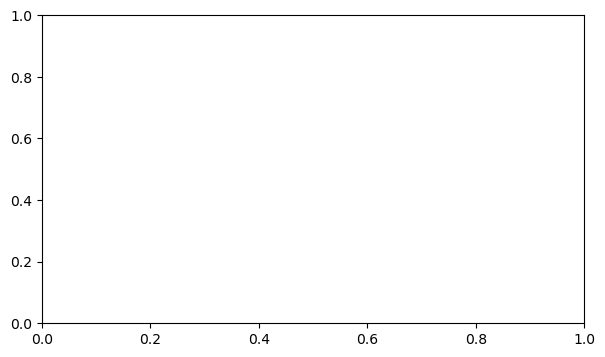

In [24]:

features_for_boxplot = [
    "gpa",
    "attendance_rate",
    "delay_count",
    "max_delay_days",
    "on_time_payment_count",
    "semester_fee",
    "distance_from_university"
]

for col in features_for_boxplot:
    on_time_values = df.loc[
        df["late_payment"] == 0,
        col
    ].dropna()

    late_values = df.loc[
        df["late_payment"] == 1,
        col
    ].dropna()

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.boxplot(
        [on_time_values, late_values],
        tick_labels=["On time", "Late"]
    )

    ax.set_title(f"{col} by payment status")
    ax.set_ylabel(col)

    fig.tight_layout()
    plt.show()


## 16.5 نسبة التأخر ضمن بعض المتغيرات الفئوية

In [ ]:

categorical_eda_features = [
    "previous_payment_delay",
    "previous_unpaid_fees",
    "works_while_studying",
    "payment_responsible",
    "family_monthly_income",
    "study_year",
    "housing"
]

for col in categorical_eda_features:
    table = pd.crosstab(
        df[col],
        df["late_payment"],
        normalize="index"
    ).rename(
        columns={
            0: "on_time_ratio",
            1: "late_ratio"
        }
    )

    print("\n" + "=" * 80)
    print(col)

    display(
        table.sort_values(
            "late_ratio",
            ascending=False
        ).round(4)
    )


## 16.6 مصفوفة الارتباط للأعمدة الرقمية

In [ ]:

corr_df = (
    df.select_dtypes(include=np.number)
    .drop(columns=["late_payment"], errors="ignore")
)

corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(13, 10))

image = ax.imshow(
    corr_matrix,
    aspect="auto"
)

fig.colorbar(image, ax=ax)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))

ax.set_xticklabels(
    corr_matrix.columns,
    rotation=90
)

ax.set_yticklabels(
    corr_matrix.columns
)

ax.set_title("Correlation Matrix - Numeric Features")

fig.tight_layout()
plt.show()


# 17. حفظ نسخة البيانات المنظفة

In [ ]:

CLEAN_DATA_PATH = DATA_DIR / "dataset-students-cleaned.csv"

df.to_csv(
    CLEAN_DATA_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("تم حفظ البيانات المنظفة:")
print(CLEAN_DATA_PATH)


# 18. تجهيز X و y


سنستبعد:

- `timestamp` لأنه يمثل وقت تعبئة الاستبيان وليس خاصية عن الطالب.
- `paid_last_installment_on_time` لأنه الهدف الأصلي.
- `late_payment` لأنه الهدف المرمز.

أما معلومات تاريخ الدفع السابق فتبقى Features لأنها معلومات يفترض أنها معروفة قبل التنبؤ بالقسط القادم.


In [ ]:

DROP_FROM_FEATURES = [
    "timestamp",
    "paid_last_installment_on_time",
    "late_payment"
]

X = df.drop(columns=DROP_FROM_FEATURES)
y = df["late_payment"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()


# 19. تحديد الأعمدة الرقمية والفئوية

In [ ]:

categorical_features = X.select_dtypes(
    include="object"
).columns.tolist()

numeric_features = X.select_dtypes(
    exclude="object"
).columns.tolist()

print("Categorical Features:")
for col in categorical_features:
    print("-", col)

print("\nNumeric Features:")
for col in numeric_features:
    print("-", col)


# 20. تقسيم البيانات إلى Training و Test


سنستخدم:
- 80% للتدريب.
- 20% للاختبار النهائي.
- `stratify=y` للحفاظ على نسبة الفئات.

لن نستخدم Test Set لاختيار النموذج.


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training X:", X_train.shape)
print("Testing X :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True).round(4))


# 21. بناء Preprocessing Pipeline


### Numeric Pipeline
1. تعويض القيم المفقودة بالـ Median.
2. StandardScaler.

### Categorical Pipeline
1. تعويض القيم المفقودة بالقيمة الأكثر تكرارًا.
2. One-Hot Encoding.
3. تجاهل الفئات الجديدة غير الموجودة أثناء التدريب.

كل ذلك داخل Pipeline لمنع Data Leakage.


In [ ]:

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numeric_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)

preprocessor


# 22. Baseline Model


قبل النماذج الحقيقية نستخدم `DummyClassifier`.

الهدف: التأكد أن نماذجنا تتفوق على نموذج بسيط لا يتعلم علاقات حقيقية.


In [ ]:

baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DummyClassifier(
                strategy="most_frequent"
            )
        )
    ]
)

baseline_model.fit(
    X_train,
    y_train
)

baseline_prediction = baseline_model.predict(
    X_test
)

baseline_metrics = {
    "accuracy": accuracy_score(
        y_test,
        baseline_prediction
    ),
    "precision": precision_score(
        y_test,
        baseline_prediction,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        baseline_prediction,
        zero_division=0
    ),
    "f1": f1_score(
        y_test,
        baseline_prediction,
        zero_division=0
    )
}

pd.DataFrame([baseline_metrics]).round(4)


# 23. Cross Validation

In [ ]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


# 24. مقارنة أولية بين النماذج الثلاثة قبل Hyperparameter Tuning

In [ ]:

candidate_models = {
    "Logistic Regression":
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1
        ),

    "SVM":
        SVC(
            probability=False,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
}


In [ ]:

initial_cv_rows = []

for model_name, model in candidate_models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    initial_cv_rows.append({
        "model": model_name,
        "accuracy": scores["test_accuracy"].mean(),
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f1": scores["test_f1"].mean(),
        "roc_auc": scores["test_roc_auc"].mean()
    })


initial_model_comparison = pd.DataFrame(
    initial_cv_rows
).sort_values(
    "f1",
    ascending=False
).reset_index(drop=True)


initial_model_comparison.round(4)


# 25. Hyperparameter Tuning للنماذج الثلاثة


سنستخدم `GridSearchCV`.

مقياس الاختيار الأساسي هو:

`F1-score`

لأنه يوازن بين Precision وRecall للحالة المهمة لدينا وهي الطالب المتأخر.


In [ ]:

search_spaces = {

    "Logistic Regression": (
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        {
            "model__C": [
                0.1,
                0.5,
                1,
                5
            ]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        {
            "model__n_estimators": [
                200,
                400
            ],
            "model__max_depth": [
                None,
                5
            ],
            "model__min_samples_leaf": [
                1,
                4
            ]
        }
    ),

    "SVM": (
        SVC(
            probability=False,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        {
            "model__C": [
                0.5,
                1,
                2
            ],
            "model__gamma": [
                "scale",
                "auto"
            ]
        }
    )
}


In [ ]:

grid_search_results = []
best_estimators = {}
best_params_by_model = {}

for model_name, (model, param_grid) in search_spaces.items():

    print("=" * 80)
    print("Tuning:", model_name)

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=1,
        refit=True
    )

    grid.fit(
        X_train,
        y_train
    )

    best_estimators[model_name] = grid.best_estimator_
    best_params_by_model[model_name] = grid.best_params_

    grid_search_results.append({
        "model": model_name,
        "best_cv_f1": grid.best_score_,
        "best_params": grid.best_params_
    })

    print("Best F1:", round(grid.best_score_, 4))
    print("Best Parameters:", grid.best_params_)


grid_results_df = pd.DataFrame(
    grid_search_results
).sort_values(
    "best_cv_f1",
    ascending=False
).reset_index(drop=True)

grid_results_df


# 26. المقارنة النهائية بين النماذج بعد ضبط Hyperparameters


هذه هي المقارنة التي سنحفظها للـ Frontend.

هي نتائج Cross Validation على Training Set للنماذج بعد استخدام أفضل Hyperparameters.


In [ ]:

final_comparison_rows = []

for model_name, tuned_model in best_estimators.items():

    scores = cross_validate(
        tuned_model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    final_comparison_rows.append({
        "model": model_name,

        "accuracy": scores["test_accuracy"].mean(),
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f1": scores["test_f1"].mean(),
        "roc_auc": scores["test_roc_auc"].mean(),

        "accuracy_std": scores["test_accuracy"].std(),
        "precision_std": scores["test_precision"].std(),
        "recall_std": scores["test_recall"].std(),
        "f1_std": scores["test_f1"].std(),
        "roc_auc_std": scores["test_roc_auc"].std()
    })


final_model_comparison = pd.DataFrame(
    final_comparison_rows
).sort_values(
    "f1",
    ascending=False
).reset_index(drop=True)


final_model_comparison.round(4)


# 27. رسم مقارنة النماذج

In [ ]:

comparison_plot_data = (
    final_model_comparison
    .set_index("model")[
        [
            "accuracy",
            "precision",
            "recall",
            "f1"
        ]
    ]
)

ax = comparison_plot_data.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title(
    "Tuned Model Performance Comparison"
)

ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ]
)

plt.tight_layout()

comparison_figure_path = (
    FIGURES_DIR /
    "model_comparison.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print(
    "تم حفظ الرسم:",
    comparison_figure_path
)


# 28. اختيار النموذج الأفضل

In [ ]:
best_model_name = final_model_comparison.loc[
    0,
    "model"
]

print("النموذج الأفضل:", best_model_name)
print(
    "F1 CV:",
    round(
        final_model_comparison.loc[0, "f1"],
        4
    )
)

print("\nBest Parameters:")
print(
    best_params_by_model[
        best_model_name
    ]
)

# أثناء Tuning استخدمنا SVM بدون probability=True لتسريع التدريب.
# إذا كان SVM هو الأفضل، نعيد بناء Pipeline بنفس أفضل الإعدادات
# مع probability=True حتى يستطيع الـ Backend إرجاع احتمالات.
if best_model_name == "SVM":

    svm_params = {
        key.replace("model__", ""): value
        for key, value in best_params_by_model["SVM"].items()
    }

    final_svm = SVC(
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        **svm_params
    )

    best_model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", final_svm)
        ]
    )

else:
    best_model = best_estimators[
        best_model_name
    ]


# 29. حفظ مقارنة النماذج للـ Frontend

هذا الملف لا يصدر قرارًا جديدًا.

وظيفته فقط أن يسمح للواجهة بعرض تنويه مثل:

> تم تدريب وتقييم عدة نماذج، وتم اعتماد النموذج الأعلى أداءً لإصدار النتيجة الحالية.

ثم يعرض مخطط المقارنة.


In [ ]:

comparison_data = {
    "selection_metric": "f1",
    "comparison_method":
        "5-fold stratified cross-validation on training set",
    "best_model": best_model_name,
    "models": []
}


for _, row in final_model_comparison.iterrows():

    comparison_data["models"].append({
        "name": row["model"],

        "accuracy":
            round(float(row["accuracy"]), 4),

        "precision":
            round(float(row["precision"]), 4),

        "recall":
            round(float(row["recall"]), 4),

        "f1":
            round(float(row["f1"]), 4),

        "roc_auc":
            round(float(row["roc_auc"]), 4),

        "is_best":
            bool(
                row["model"] ==
                best_model_name
            )
    })


COMPARISON_PATH = (
    MODELS_DIR /
    "model_comparison.json"
)


with open(
    COMPARISON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        comparison_data,
        f,
        ensure_ascii=False,
        indent=2
    )


print("تم حفظ مقارنة النماذج:")
print(COMPARISON_PATH)

comparison_data


# 30. التقييم النهائي للنموذج الأفضل على Test Set


الآن فقط نستخدم Test Set لتقييم النموذج الذي تم اختياره.

هذا هو التقييم النهائي الذي نعتمده في التقرير العلمي.


In [ ]:

# نعيد التأكد من تدريب النموذج الأفضل على كامل Training Set.
best_model.fit(
    X_train,
    y_train
)

y_pred = best_model.predict(
    X_test
)

y_proba_late = best_model.predict_proba(
    X_test
)[:, 1]


test_metrics = {
    "accuracy":
        accuracy_score(
            y_test,
            y_pred
        ),

    "precision":
        precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),

    "recall":
        recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),

    "f1":
        f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),

    "roc_auc":
        roc_auc_score(
            y_test,
            y_proba_late
        ),

    "average_precision":
        average_precision_score(
            y_test,
            y_proba_late
        )
}


pd.DataFrame(
    [test_metrics]
).round(4)


## 30.1 Classification Report

In [ ]:

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "On Time",
            "Late"
        ],
        digits=4
    )
)


## 30.2 Confusion Matrix

In [ ]:

fig, ax = plt.subplots(
    figsize=(6, 5)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=[
        "On Time",
        "Late"
    ],
    ax=ax
)

ax.set_title(
    f"Confusion Matrix - {best_model_name}"
)

fig.tight_layout()

confusion_matrix_path = (
    FIGURES_DIR /
    "confusion_matrix.png"
)

fig.savefig(
    confusion_matrix_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print(
    "تم حفظ الرسم:",
    confusion_matrix_path
)


## 30.3 ROC Curve

In [ ]:

fig, ax = plt.subplots(
    figsize=(6, 5)
)

RocCurveDisplay.from_predictions(
    y_test,
    y_proba_late,
    ax=ax
)

ax.set_title(
    f"ROC Curve - {best_model_name}"
)

fig.tight_layout()

roc_path = (
    FIGURES_DIR /
    "roc_curve.png"
)

fig.savefig(
    roc_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("تم حفظ الرسم:", roc_path)


## 30.4 Precision-Recall Curve

In [ ]:

fig, ax = plt.subplots(
    figsize=(6, 5)
)

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_proba_late,
    ax=ax
)

ax.set_title(
    f"Precision-Recall Curve - {best_model_name}"
)

fig.tight_layout()

pr_path = (
    FIGURES_DIR /
    "precision_recall_curve.png"
)

fig.savefig(
    pr_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("تم حفظ الرسم:", pr_path)


# 31. تحليل الأخطاء

In [ ]:

error_analysis = X_test.copy()

error_analysis["actual_late"] = y_test.values
error_analysis["predicted_late"] = y_pred
error_analysis["probability_late"] = y_proba_late
error_analysis["probability_on_time"] = (
    1 - y_proba_late
)

false_negatives = error_analysis[
    (error_analysis["actual_late"] == 1) &
    (error_analysis["predicted_late"] == 0)
].sort_values(
    "probability_late"
)

false_positives = error_analysis[
    (error_analysis["actual_late"] == 0) &
    (error_analysis["predicted_late"] == 1)
].sort_values(
    "probability_late",
    ascending=False
)

print(
    "False Negatives:",
    len(false_negatives)
)

print(
    "False Positives:",
    len(false_positives)
)


## 31.1 False Negatives

In [ ]:

false_negatives.head(10)


## 31.2 False Positives

In [ ]:

false_positives.head(10)


# 32. أهم العوامل المؤثرة


نستخدم `Permutation Importance`.

هذه الطريقة تقيس مقدار انخفاض F1 عند خلط Feature معينة.

> الأهمية هنا **تنبؤية** وليست دليلًا على علاقة سببية.


In [ ]:

perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1
)


feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean":
        perm.importances_mean,
    "importance_std":
        perm.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)


feature_importance.round(4)


In [ ]:

top_features = (
    feature_importance
    .head(15)
    .sort_values(
        "importance_mean"
    )
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.barh(
    top_features["feature"],
    top_features["importance_mean"]
)

ax.set_xlabel(
    "Permutation Importance"
)

ax.set_title(
    f"Top Features - {best_model_name}"
)

fig.tight_layout()

importance_path = (
    FIGURES_DIR /
    "feature_importance.png"
)

fig.savefig(
    importance_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print(
    "تم حفظ الرسم:",
    importance_path
)


# 33. حفظ النموذج النهائي


نحفظ **Pipeline كاملة** وليس المصنف وحده.

وهذا يعني أن الملف يحتوي على:
- Imputer
- StandardScaler
- One-Hot Encoder
- Best Classifier

لذلك يستطيع FastAPI إرسال بيانات الطالب الخام للنموذج مباشرة.


In [ ]:

MODEL_PATH = (
    MODELS_DIR /
    "student_payment_classifier.joblib"
)

joblib.dump(
    best_model,
    MODEL_PATH
)

print(
    "تم حفظ النموذج النهائي:"
)

print(MODEL_PATH)


# 34. حفظ Metadata

In [ ]:

metadata = {
    "model_name":
        best_model_name,

    "selection_metric":
        "f1",

    "positive_class":
        {
            "value": 1,
            "meaning": "late_payment"
        },

    "target_definition":
        {
            "0": "paid_on_time",
            "1": "late_payment"
        },

    "features":
        X.columns.tolist(),

    "categorical_features":
        categorical_features,

    "numeric_features":
        numeric_features,

    "best_parameters":
        best_params_by_model[
            best_model_name
        ],

    "test_metrics":
        {
            key: round(
                float(value),
                6
            )
            for key, value
            in test_metrics.items()
        },

    "comparison_file":
        "model_comparison.json",

    "compared_models":
        final_model_comparison[
            "model"
        ].tolist(),

    "cleaning_summary":
        {
            "raw_rows":
                int(len(df_raw)),

            "final_rows":
                int(len(df)),

            "duplicates_removed":
                int(duplicate_count),

            "previous_payment_delay_corrections":
                int(consistency_changes),

            "invalid_numeric_values_converted_to_nan":
                invalid_value_report
        }
}


METADATA_PATH = (
    MODELS_DIR /
    "student_payment_classifier_metadata.json"
)


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        ensure_ascii=False,
        indent=2
    )


print("تم حفظ Metadata:")
print(METADATA_PATH)


# 35. التأكد من الملفات الناتجة

In [ ]:

generated_files = [
    CLEAN_DATA_PATH,
    MODEL_PATH,
    METADATA_PATH,
    COMPARISON_PATH,
    FIGURES_DIR / "target_distribution.png",
    FIGURES_DIR / "model_comparison.png",
    FIGURES_DIR / "confusion_matrix.png",
    FIGURES_DIR / "roc_curve.png",
    FIGURES_DIR / "precision_recall_curve.png",
    FIGURES_DIR / "feature_importance.png"
]

for file_path in generated_files:
    print(
        "OK" if file_path.exists() else "MISSING",
        "->",
        file_path
    )


# 36. تحميل النموذج من الملف للتأكد من أنه يعمل

In [ ]:

loaded_model = joblib.load(
    MODEL_PATH
)

sample_student = (
    X_test.iloc[[0]].copy()
)

sample_prediction = int(
    loaded_model.predict(
        sample_student
    )[0]
)

sample_late_probability = float(
    loaded_model.predict_proba(
        sample_student
    )[0, 1]
)

sample_on_time_probability = (
    1 - sample_late_probability
)

print(
    "Prediction:",
    sample_prediction
)

print(
    f"Late probability: "
    f"{sample_late_probability:.2%}"
)

print(
    f"On-time probability: "
    f"{sample_on_time_probability:.2%}"
)

sample_student


# 37. دالة تنبؤ جاهزة لمنطق الـ Backend

In [ ]:

def predict_student_payment(
    model,
    student_data: dict
):
    student_df = pd.DataFrame(
        [student_data]
    )

    predicted_class = int(
        model.predict(
            student_df
        )[0]
    )

    late_probability = float(
        model.predict_proba(
            student_df
        )[0, 1]
    )

    on_time_probability = (
        1 - late_probability
    )

    return {
        "prediction":
            (
                "late"
                if predicted_class == 1
                else "on_time"
            ),

        "late_probability":
            late_probability,

        "on_time_probability":
            on_time_probability,

        "model":
            best_model_name
    }


example_student = (
    X_test.iloc[0].to_dict()
)

example_result = (
    predict_student_payment(
        loaded_model,
        example_student
    )
)

example_result



# 38. الشكل المتوقع لاستجابة FastAPI لاحقًا

القرار النهائي سيأتي من النموذج الأفضل فقط:

```json
{
  "prediction": "late",
  "late_probability": 0.73,
  "on_time_probability": 0.27,
  "model": "Best Model Name"
}
```

أما مقارنة النماذج الثلاثة فتقرأ بشكل مستقل من:

```text
models/model_comparison.json
```

ويمكن للواجهة عرضها أسفل النتيجة كتوضيح فقط، وليس كتصويت بين النماذج.



# 39. ملاحظة علمية مهمة عن عدد أيام التأخير

نص المشروع يطلب أيضًا تقدير عدد أيام التأخير إذا لم يدفع الطالب في الموعد.

لكن الـ Dataset الحالية لا تحتوي على Target صريح يمثل:

`عدد أيام تأخر القسط الأخير`

الموجود هو:

`max_delay_days`

أي:

**أقصى مدة تأخير سابقة للطالب**

وهذا تاريخ سابق، وليس عدد أيام التأخير الحقيقي للقسط الذي نريد توقعه.

لذلك لا يصح علميًا تدريب Regression Model على `max_delay_days` ثم الادعاء أنه يتنبأ بعدد أيام تأخر القسط القادم.

### ما الذي نحتاجه؟

إضافة عمود مثل:

```text
last_installment_delay_days
```

ويكون:
- `0` عندما دفع القسط الأخير في الموعد.
- عدد الأيام الفعلية عندما تأخر.

بعد جمع هذا العمود يمكن بناء نموذج Regression مستقل للطلاب المتأخرين.


In [ ]:

REGRESSION_TARGET = (
    "last_installment_delay_days"
)

if REGRESSION_TARGET in df.columns:
    print(
        "Target الخاص بالـ Regression موجود، "
        "ويمكن بناء نموذج عدد أيام التأخير."
    )
else:
    print(
        "لم يتم بناء Regression Model لأن "
        f"{REGRESSION_TARGET!r} غير موجود في الداتا الحالية."
    )



# 40. Checklist المشروع

## البيانات والمعالجة
- [x] قراءة البيانات.
- [x] فحص الأعمدة والأنواع.
- [x] تنظيف النصوص.
- [x] توحيد الأخطاء الكتابية.
- [x] اكتشاف القيم غير المنطقية.
- [x] معالجة التناقضات الداخلية.
- [x] حذف التكرارات.
- [x] فحص القيم المفقودة.
- [x] فحص القيم الشاذة.
- [x] حفظ نسخة منظفة.

## EDA
- [x] وصف إحصائي.
- [x] توزيع Target.
- [x] توزيعات Features.
- [x] Boxplots.
- [x] علاقات الفئات بالهدف.
- [x] Correlation Matrix.

## بناء النموذج
- [x] تحديد X و y.
- [x] Train/Test Split.
- [x] منع Data Leakage.
- [x] Imputation داخل Pipeline.
- [x] Scaling.
- [x] One-Hot Encoding.
- [x] Baseline.
- [x] Logistic Regression.
- [x] Random Forest.
- [x] SVM.
- [x] Cross Validation.
- [x] Hyperparameter Tuning.
- [x] Accuracy.
- [x] Precision.
- [x] Recall.
- [x] F1-score.
- [x] ROC-AUC.
- [x] اختيار أفضل نموذج.
- [x] Test Set Evaluation.
- [x] Confusion Matrix.
- [x] ROC Curve.
- [x] Precision-Recall Curve.
- [x] Error Analysis.
- [x] Feature Importance.

## ملفات النظام
- [x] حفظ أفضل نموذج.
- [x] حفظ Metadata.
- [x] حفظ مقارنة النماذج للواجهة.
- [x] تجربة تحميل النموذج.
- [x] دالة Prediction.
- [ ] Regression لعدد أيام التأخير: يحتاج Target حقيقي.

---

## الخطوة التالية

بعد نجاح تشغيل هذا الملف بالكامل:

1. نبني `backend/main.py` باستخدام FastAPI.
2. نحمل `student_payment_classifier.joblib`.
3. نبني `/predict`.
4. نبني Endpoint لقراءة `model_comparison.json`.
5. نربط الـ Frontend.
6. تعرض الواجهة القرار النهائي من أفضل نموذج فقط، ثم مقارنة النماذج كتوضيح أسفل النتيجة.
